# 커스텀 감사 미들웨어

**이 노트북에서 할 일**

1. 개인정보 원문 대신 지문(해시)을 남기는 함수를 만듭니다.
2. 에이전트 시작·도구 호출·종료를 기록하는 감사 훅 세 개를 만듭니다.
3. 이메일이 든 질문으로 실행하고, 기록에 원문이 남지 않았는지 확인합니다.

**준비물** — `.env` 파일의 `OPENAI_API_KEY`. 데이터 파일은 없습니다. 모델 호출은 2번이고 실행 시간은 1분 이내입니다. 예상 비용은 0.01달러 미만입니다.

## 오늘 볼 그림

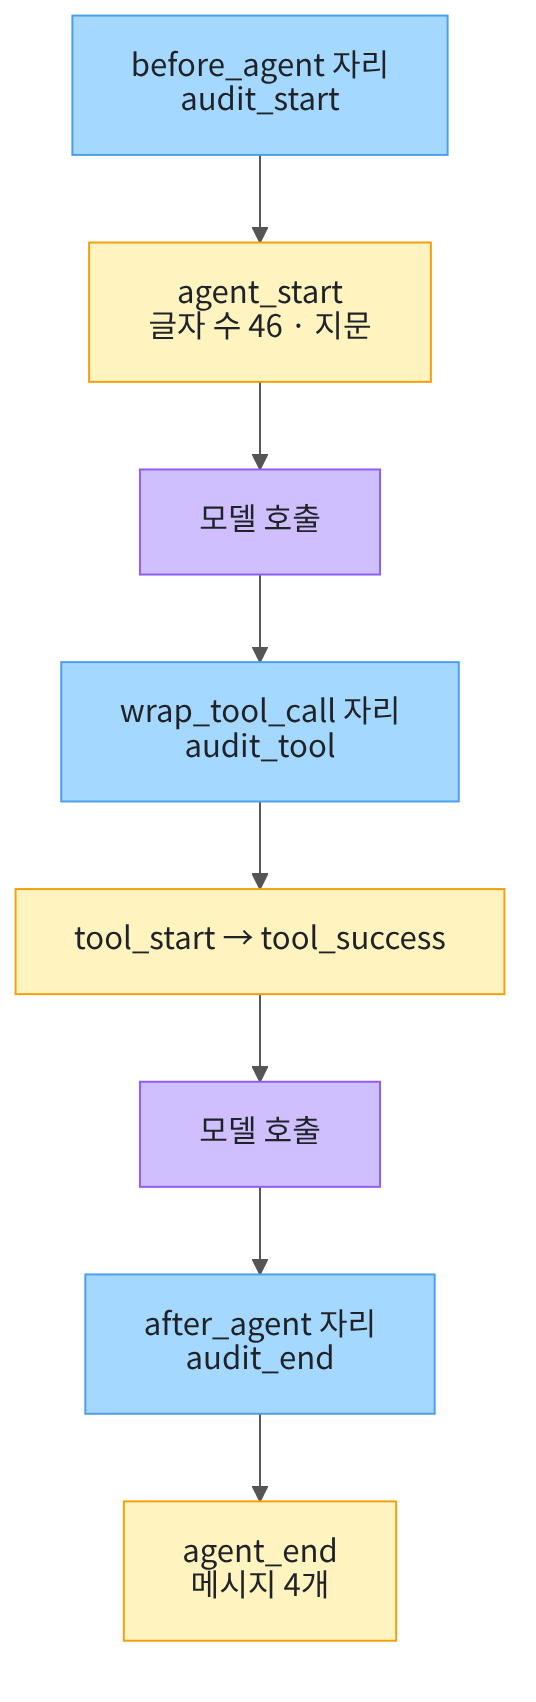

에이전트 시작, 도구 호출 앞뒤, 에이전트 종료에서 사건 하나씩이 기록됩니다. 기록에는 질문 원문이 들어가지 않습니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11


이번 절에서 쓰는 이름을 불러옵니다. 지문은 파이썬 기본 모듈 `hashlib`으로 만듭니다.

In [2]:
# 지문·기록·에이전트·훅·도구·모델을 만드는 도구를 불러옵니다
import hashlib
import json
from collections.abc import Callable

from langchain.agents import create_agent
from langchain.agents.middleware import AgentState, Runtime, ToolCallRequest
from langchain.agents.middleware import after_agent, before_agent, wrap_tool_call
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langchain_core.messages import ToolMessage

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다. 01절과 같은 설정입니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-15에 이 모델로 실행한 결과입니다.

## 2. 원문 대신 지문 남기기

감사 기록(audit log)은 나중에 「언제 어떤 실행이 있었고 어떤 도구가 쓰였나」를 확인하기 위한 사건 목록입니다.
질문 원문을 그대로 기록하면 기록 파일에 개인정보가 쌓입니다. 그래서 원문 대신 지문을 남깁니다.
지문(해시)은 글을 정해진 규칙으로 섞어 만든 짧은 문자열입니다. 같은 글은 같은 지문이 되지만, 지문만 보고 원문을 알아내기는 어렵습니다.

In [5]:
# 글을 받아 10글자짜리 지문을 만드는 함수
def fingerprint(text: str) -> str:
    data = ("lesson-salt:" + text).encode("utf-8")
    digest = hashlib.sha256(data).hexdigest()
    return digest[:10]


print("지문 예시:", fingerprint("learner@example.com"))

지문 예시: 367129c879


**결과 읽기** — 지문 예시로 `367129c879`처럼 영문과 숫자 10글자가 나옵니다. 이 안에 `learner@example.com`이라는 글자는 없습니다.
글 앞에 `lesson-salt:`를 붙이는 이유는, 흔한 글의 지문을 미리 만들어 둔 표로 원문을 짐작하기 어렵게 하기 위해서입니다.

## 3. 감사 훅 세 개 만들기

사건을 담을 빈 목록을 만듭니다.

In [6]:
# 감사 사건을 담을 빈 목록을 만듭니다
events = []
print("사건 수:", len(events))

사건 수: 0


**결과 읽기** — 사건 수는 `0`입니다.

첫 번째 훅은 에이전트가 시작할 때 질문의 글자 수와 지문을 기록합니다. 원문은 기록하지 않습니다.

In [7]:
# 에이전트 시작 사건을 기록하는 훅
@before_agent
def audit_start(state: AgentState, runtime: Runtime) -> None:
    first_text = state["messages"][0].text
    event = {"event": "agent_start", "input_chars": len(first_text), "fingerprint": fingerprint(first_text)}
    events.append(event)

출력은 없습니다.

두 번째 훅은 도구 호출을 감쌉니다. 호출 전에 시작 사건을, 성공하면 성공 사건을, 오류가 나면 오류 사건을 남깁니다.
예외 처리 문법인 `try`와 `except`는 Ch2 05절에서 배웠습니다.

오류 사건의 `type(error).__name__` 값은 오류 종류 이름(예: `ValueError`)을 글로 꺼낸 것입니다.
이 훅은 오류를 기록한 뒤 단독 `raise` 줄로 방금 잡은 오류를 그대로 다시 올려 보냅니다.

In [8]:
# 도구 호출의 시작·성공·오류를 기록하는 훅
@wrap_tool_call
def audit_tool(request: ToolCallRequest, handler: Callable) -> ToolMessage:
    tool_name = request.tool_call["name"]
    events.append({"event": "tool_start", "tool": tool_name})
    try:
        result = handler(request)
    except Exception as error:
        events.append({"event": "tool_error", "tool": tool_name, "error": type(error).__name__})
        raise
    events.append({"event": "tool_success", "tool": tool_name})
    return result

출력은 없습니다.

세 번째 훅은 에이전트가 끝날 때 대화 기록의 메시지 수를 남깁니다.

In [9]:
# 에이전트 종료 사건을 기록하는 훅
@after_agent
def audit_end(state: AgentState, runtime: Runtime) -> None:
    events.append({"event": "agent_end", "messages": len(state["messages"])})

출력은 없습니다.

## 4. 이메일이 든 질문으로 실행하기

01절의 운영 시간 도구를 다시 만듭니다.

In [10]:
# 자료실 운영 시간을 알려 주는 도구를 만듭니다
@tool
def lookup_hours(day: str) -> str:
    """자료실 운영 시간을 조회합니다. day에는 "평일" 또는 "토요일"을 넣습니다."""
    if day == "평일":
        return "평일 09:00~20:00"
    return "토요일 10:00~17:00"


print("도구 이름:", lookup_hours.name)

도구 이름: lookup_hours


**결과 읽기** — 도구 이름 `lookup_hours`가 출력됩니다.

감사 훅 세 개를 등록하고, 이메일이 든 질문을 보냅니다.

In [11]:
# 감사 훅을 등록하고 이메일이 든 질문으로 실행합니다
events.clear()
audit_agent = create_agent(model, tools=[lookup_hours], middleware=[audit_start, audit_tool, audit_end])
question = "learner@example.com 입니다. 자료실 평일 운영 시간을 알려 주세요."
audit_result = audit_agent.invoke({"messages": [{"role": "user", "content": question}]})
print("최종 답:", audit_result["messages"][-1].text)
for event in events:
    print(event)

최종 답: 자료실 평일 운영 시간은 **09:00~20:00**입니다.
{'event': 'agent_start', 'input_chars': 46, 'fingerprint': '36bbd90c50'}
{'event': 'tool_start', 'tool': 'lookup_hours'}
{'event': 'tool_success', 'tool': 'lookup_hours'}
{'event': 'agent_end', 'messages': 4}


**결과 읽기** — 사건이 `agent_start`, `tool_start`, `tool_success`, `agent_end` 순서로 기록됐습니다.
시작 사건에는 글자 수와 지문만 있고, 종료 사건에는 메시지 수만 있습니다. 최종 답 문장은 실행마다 달라질 수 있습니다.

In [12]:
# 기록 전체를 글로 바꿔 이메일 원문이 들어 있는지 확인합니다
saved_text = json.dumps(events, ensure_ascii=False)
has_email = "learner@example.com" in saved_text
print("기록에 이메일 원문이 있나:", has_email)
print("첫 사건:", events[0]["event"], "/ 마지막 사건:", events[-1]["event"])
assert not has_email
assert events[0]["event"] == "agent_start"
assert events[-1]["event"] == "agent_end"

기록에 이메일 원문이 있나: False
첫 사건: agent_start / 마지막 사건: agent_end


**결과 읽기** — 기록에 이메일 원문이 있는지 확인한 결과는 `False`입니다. 첫 사건은 `agent_start`, 마지막 사건은 `agent_end`입니다.

## 5. 값 하나 바꿔 보기 — 글자 수가 같은 두 글

글자 수만 기록하면 서로 다른 질문을 구분할 수 없습니다. 글자 수가 같은 두 글의 지문을 비교합니다.

In [13]:
# 글자 수가 같은 두 글의 지문을 비교합니다
text_a = "대출 연장 문의"
text_b = "반납 기한 문의"
print("글자 수:", len(text_a), len(text_b))
print("지문:", fingerprint(text_a), fingerprint(text_b))
print("지문이 서로 다른가:", fingerprint(text_a) != fingerprint(text_b))
print("같은 글의 지문이 같은가:", fingerprint(text_a) == fingerprint("대출 연장 문의"))

글자 수: 8 8
지문: 86841b132e 38802a48c3
지문이 서로 다른가: True
같은 글의 지문이 같은가: True


**결과 읽기** — 두 글의 글자 수는 같지만 지문이 서로 다르다는 결과가 `True`입니다.
같은 글을 다시 넣으면 지문도 같았습니다. 그래서 지문을 남기면 원문 없이도 「같은 질문이 반복됐는지」는 알 수 있습니다.

## 정리

- 감사 훅은 실행의 시작·도구 호출·종료에서 사건을 하나씩 기록했습니다.
- 개인정보가 들어갈 수 있는 원문 대신 글자 수와 지문을 남겼습니다.
- 도구 오류는 기록한 뒤 `raise`로 다시 올려 보내도록 만들었습니다. 오류가 난 실행은 이번에 관찰하지 않았습니다.